# Replication and counter-screens

#### Objectives
Replicate the α counter-screen across four seeds, add the sibling sequence `_0` to the panel, screen all designs for self-association, and establish whether the single-seed verdicts from Stage 5 (Boltz2) survive.

#### Methodology
Four seeds (0-3) per design on the α panel only, since that is the panel carrying the project's selectivity claim. Replication is reported three ways, because they answer different questions: confidence (ipTM, interface PAE) measures how sure the model is buried surface area measures how large an interface it builds. The identity of the
contacting residues measures, however, whether it puts the interface in the same place at all. <br>
Self-association is screened by predicting each sequence against a copy of itself. Native
IL-2 and Neo-2/15 are included. Both of them are monomeric, so both should score low. <br>
The β/γc threshold is the scrambled control's interface PAE; the α thresholds are Neo-2/15's own ipTM (0.761) and interface PAE (14.31). A design passes if it disengages from IL-2Rα at least as well as the validated selective reference.

In [ ]:
from google.colab import drive
drive.flush_and_unmount()
print("unmounted")

Drive not mounted, so nothing to flush and unmount.
unmounted


In [ ]:
import os
from google.colab import drive
drive.mount("/content/drive")

PROJ  = "/content/drive/MyDrive/il2_mimetic"
PROBE = f"{PROJ}/stage1_motif/params.json"
assert os.path.isfile(PROBE), f"{PROBE} still not visible"
print("project visible:", sorted(os.listdir(PROJ))[:6])

In [ ]:
import shutil, os
from google.colab import drive

shutil.rmtree("/content/drive", ignore_errors=True)
print("removed:", not os.path.exists("/content/drive"))

drive.mount("/content/drive")

PROJ  = "/content/drive/MyDrive/il2_mimetic"
PROBE = f"{PROJ}/stage1_motif/params.json"
assert os.path.isfile(PROBE), f"{PROBE} still not visible"
print("project visible:", sorted(os.listdir(PROJ))[:6])

removed: True
Mounted at /content/drive
project visible: ['2B5I.pdb', 'af2_37_s0_f996d.result.zip', 'af2_crosscheck', 'af2_ctrl_IL2_s0_85434_0.result.zip', 'af2_ctrl_Neo_s0_fb45a.result.zip', 'analysis_additional']


In [ ]:
# Rebuild the Boltz environment and the narrow-allowlist wrapper. Identical
# to Stage 5 and repeated rather than imported, because a Colab session
# starts empty and a half-restored environment fails silently later
import os, subprocess, textwrap, glob

# ---- 1. Drive ----
from google.colab import drive
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")
PROJ = "/content/drive/MyDrive/il2_mimetic"
assert os.path.isfile(f"{PROJ}/stage1_motif/params.json"), "wrong Drive account?"

# ---- 2. Boltz, without letting pip replace the CUDA torch build ----
os.environ["WANDB_MODE"] = "offline"; os.environ["WANDB_DISABLED"] = "true"
DEPS = ["numpy","scipy","pandas","scikit-learn","numba","rdkit","biopython",
        "gemmi","modelcif","chembl_structure_pipeline","hydra-core",
        "pytorch-lightning","fairscale","dm-tree","einops","einx","mashumaro",
        "click","pyyaml","requests","types-requests","wandb"]   # deliberately no torch
subprocess.run(["pip","-q","install"]+DEPS, check=True)
subprocess.run(["pip","-q","install","boltz==2.2.1","--no-deps",
                "--ignore-requires-python"], check=True)

cuda = subprocess.run(["python","-c","import torch; print(torch.version.cuda or 'NONE')"],
                      capture_output=True, text=True).stdout.strip()
assert cuda != "NONE", "torch lost its CUDA build — do not proceed"
print("torch cuda:", cuda)

# ---- 3. wrapper: narrow unpickling allowlist for the checkpoint ----
os.makedirs("/content/tools", exist_ok=True)
with open("/content/tools/boltz_run.py","w") as fh:
    fh.write(textwrap.dedent('''
        """Run the Boltz CLI with a narrow torch.load allowlist.

        torch>=2.6 loads checkpoints with weights_only=True because pickle can
        name any callable. Boltz-2's checkpoint embeds an omegaconf DictConfig.
        We permit those config classes only — NOT weights_only=False, which
        would re-enable arbitrary code execution.
        """
        import sys, typing, collections
        import torch.serialization as ts
        from omegaconf.dictconfig import DictConfig
        from omegaconf.listconfig import ListConfig
        from omegaconf.base import ContainerMetadata, Metadata
        from omegaconf.nodes import AnyNode, ValueNode
        ALLOWED = [DictConfig, ListConfig, ContainerMetadata, Metadata,
                   AnyNode, ValueNode, typing.Any, collections.defaultdict,
                   dict, list, int, str, float, bool]
        ts.add_safe_globals(ALLOWED)
        print(f"[boltz_run] allowlisted {len(ALLOWED)} classes", file=sys.stderr)
        from boltz.main import cli
        sys.exit(cli())
    ''').lstrip())
print("wrapper ready")

torch cuda: 13.0
wrapper ready


In [ ]:
# Run the two jobs added since Stage 5: the Round 2 sibling _0 in both
# panels. Completeness is checked against output files rather than exit
# codes, for the reason Stage 5 established, Boltz catches its own MSA
# failures and still exits 0
import os, glob, subprocess, time

PROJ = "/content/drive/MyDrive/il2_mimetic"
IN, OUT = f"{PROJ}/stage5_complex/inputs", f"{PROJ}/stage5_complex/preds"
LOG = f"{PROJ}/stage5_complex/run_log.tsv"

jobs = sorted(os.path.basename(p)[:-6] for p in glob.glob(f"{IN}/*.fasta"))
def done(j):
    d = f"{OUT}/boltz_results_{j}/predictions/{j}"
    return bool(glob.glob(f"{d}/*.pdb")) and bool(glob.glob(f"{d}/pae*.npz"))
todo = [j for j in jobs if not done(j)]
print(f"{len(jobs)} jobs · {len(jobs)-len(todo)} complete · {len(todo)} to run\n")

for i, j in enumerate(todo, 1):
    t0 = time.time()
    p = subprocess.run(
        ["python","/content/tools/boltz_run.py","predict", f"{IN}/{j}.fasta",
         "--out_dir", OUT, "--output_format","pdb", "--seed","0",
         "--accelerator","gpu", "--use_msa_server", "--no_kernels",
         "--write_full_pae", "--write_full_pde"],
        capture_output=True, text=True)
    dt = (time.time()-t0)/60
    print(f"[{i}/{len(todo)}] {'ok ' if p.returncode==0 else 'FAIL'} "
          f"{j:40s} {dt:4.1f} min  output={'yes' if done(j) else 'NO'}")
    if not done(j):
        print("   ", p.stderr.strip().splitlines()[-1][:200] if p.stderr else "(no stderr)")
    with open(LOG,"a") as fh: fh.write(f"{j}\t{p.returncode}\t{dt:.2f}\n")

29 jobs · 29 complete · 0 to run



In [ ]:
# Rebuild the metrics table over all 20 jobs, now with an assertion that
# the PAE matrix dimension matches the summed chain lengths. Stage 5
# checked this by eye; here it fails loudly, since a silent off-by-one in
# the block boundaries would corrupt every interface value
import os, glob, json
import numpy as np, pandas as pd

PROJ = "/content/drive/MyDrive/il2_mimetic"
IN, OUT = f"{PROJ}/stage5_complex/inputs", f"{PROJ}/stage5_complex/preds"

def blocks(job):
    i, rng, hdr = 0, {}, None
    for ln in open(f"{IN}/{job}.fasta"):
        ln = ln.strip()
        if ln.startswith(">"): hdr = ln[1:].split("|")[0]
        elif ln: rng[hdr] = (i, i+len(ln)); i += len(ln)
    return rng, i

def load_pae(job):
    f = glob.glob(f"{OUT}/boltz_results_{job}/predictions/{job}/pae*.npz")
    if not f: return None
    z = np.load(f[0]); return np.squeeze(z[list(z.keys())[0]])

def iface(pae, r1, r2):
    a = pae[r1[0]:r1[1], r2[0]:r2[1]]; b = pae[r2[0]:r2[1], r1[0]:r1[1]]
    return float((a.mean() + b.mean()) / 2)

rows = []
for fa in sorted(glob.glob(f"{IN}/*.fasta")):
    job = os.path.basename(fa)[:-6]
    d = f"{OUT}/boltz_results_{job}/predictions/{job}"
    cj = glob.glob(f"{d}/confidence*.json")
    if not cj: continue
    c = json.load(open(cj[0])); rng, n = blocks(job); pae = load_pae(job)
    kind = "alpha" if job.endswith("_alpha") else "ternary"
    r = dict(design=job.rsplit("_",1)[0], kind=kind, n_res=n,
             iptm=c.get("iptm"), plddt=c.get("complex_plddt"))
    if pae is not None:
        assert pae.shape[0] == n, f"{job}: PAE {pae.shape[0]} vs {n}"
        ch = list(rng)
        if kind == "ternary":
            r["pae_d_beta"] = iface(pae, rng[ch[0]], rng[ch[1]])
            r["pae_d_gc"]   = iface(pae, rng[ch[0]], rng[ch[2]])
        else:
            r["pae_d_alpha"] = iface(pae, rng[ch[0]], rng[ch[1]])
    rows.append(r)

df = pd.DataFrame(rows)
p = df.pivot_table(index="design", columns="kind", values=["iptm","plddt"],
                   aggfunc="first")
p.columns = [f"{a}_{b}" for a, b in p.columns]
tab = p.join(df.set_index("design")[["pae_d_beta","pae_d_gc","pae_d_alpha"]]
               .groupby(level=0).first())

order = ["ctrl_IL2","ctrl_Neo","ctrl_scram",
         "pad0_len100_2_fixContacts_3", "pad0_len100_2_fixContacts_0"]
order += sorted(d for d in tab.index if d not in order)
tab = tab.reindex([d for d in order if d in tab.index])

pd.set_option("display.width", 200)
print(tab.round(3).to_string())
tab.round(4).to_csv(f"{PROJ}/stage5_complex/stage5_metrics.tsv", sep="\t")

                              iptm_alpha  iptm_ternary  plddt_alpha  plddt_ternary  pae_d_beta  pae_d_gc  pae_d_alpha
design                                                                                                               
ctrl_IL2                           0.884         0.908        0.733          0.931       6.715     6.654       10.177
ctrl_Neo                           0.761         0.891        0.716          0.933       6.626     6.670       14.310
ctrl_scram                         0.706         0.870        0.646          0.834       8.878     9.062       16.535
pad0_len100_2_fixContacts_3        0.441         0.896        0.740          0.932       6.077     6.135       20.644
pad0_len100_2_fixContacts_0        0.580         0.905        0.715          0.936       5.723     5.928       16.786
pad0_len100_13_fixContacts_3       0.815         0.896        0.763          0.943       5.668     6.016       12.442
pad0_len100_15_fixAll_4            0.418         0.827  

wrote /content/drive/MyDrive/il2_mimetic/figures/selectivity_2d.png


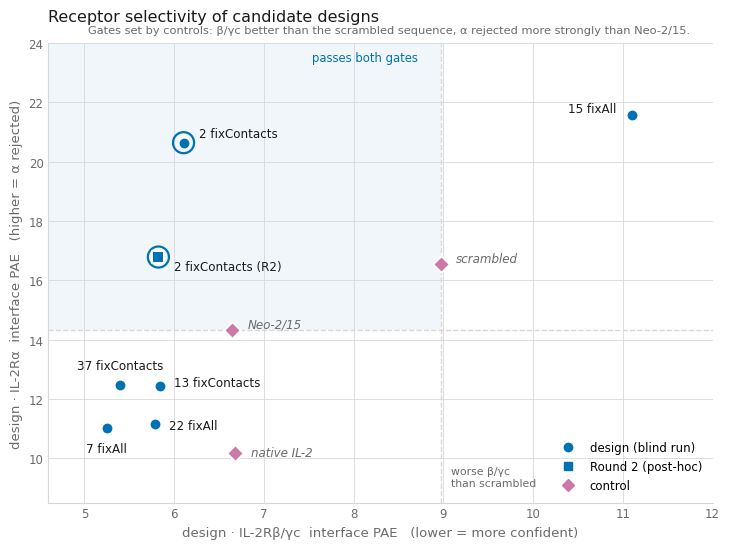

In [ ]:
# Two-dimensional selectivity view. Both gates are taken from
# controls rather than chosen: the x gate is the scrambled control's
# beta/gc interface PAE, the y gate is Neo-2/15's alpha interface PAE.
# The shaded quadrant is "engages the target better than a shuffled
# sequence, and avoids alpha at least as well as the reference"
import os
import pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

PROJ = "/content/drive/MyDrive/il2_mimetic"
FIG  = f"{PROJ}/figures"; os.makedirs(FIG, exist_ok=True)

tab = pd.read_csv(f"{PROJ}/stage5_complex/stage5_metrics.tsv", sep="\t", index_col=0)
tab["bgc"] = tab[["pae_d_beta","pae_d_gc"]].mean(axis=1)

ROUND2 = "pad0_len100_2_fixContacts_0"

def short(d):
    if d.startswith("ctrl_"):
        return {"ctrl_IL2":"native IL-2","ctrl_Neo":"Neo-2/15","ctrl_scram":"scrambled"}[d]
    p = d.split("_")
    tag = f"{p[2]} {p[3]}"
    return f"{tag} (R2)" if d == ROUND2 else tag

OFFSETS = {
    "pad0_len100_2_fixContacts_3":  ( 11,   4, "left"),
    ROUND2:                         ( 11,  -9, "left"),
    "pad0_len100_15_fixAll_4":      (-11,   2, "right"),
    "pad0_len100_37_fixContacts_2": (  0,  11, "center"),
    "pad0_len100_13_fixContacts_3": ( 10,   0, "left"),
    "pad2_len100_7_fixAll_3":       (  0, -17, "center"),
    "pad0_len100_22_fixAll_0":      ( 10,  -4, "left"),
    "ctrl_IL2":  (11, -2, "left"), "ctrl_Neo": (11, 2, "left"),
    "ctrl_scram":(11,  2, "left"),
}

DESIGN, CONTROL = "#0072B2", "#CC79A7"
INK, MUTED, RULE = "#1a1a1a", "#6b6b6b", "#d8d8d8"
X_GATE = tab.loc["ctrl_scram","bgc"]
Y_GATE = tab.loc["ctrl_Neo","pae_d_alpha"]

fig, ax = plt.subplots(figsize=(7.4, 5.6))
ax.add_patch(Rectangle((0, Y_GATE), X_GATE, 40, facecolor=DESIGN, alpha=0.06, zorder=0))
ax.axvline(X_GATE, color=RULE, lw=1, ls="--", zorder=1)
ax.axhline(Y_GATE, color=RULE, lw=1, ls="--", zorder=1)

for d, r in tab.iterrows():
    is_ctrl = d.startswith("ctrl_")
    is_r2   = d == ROUND2
    passes  = (r.bgc < X_GATE) and (r.pae_d_alpha > Y_GATE)
    c = CONTROL if is_ctrl else DESIGN
    mk = "D" if is_ctrl else ("s" if is_r2 else "o")
    if passes and not is_ctrl:
        ax.scatter(r.bgc, r.pae_d_alpha, s=230, facecolor="none",
                   edgecolor=DESIGN, lw=1.6, zorder=3)
    ax.scatter(r.bgc, r.pae_d_alpha, s=72, color=c, marker=mk, zorder=4,
               edgecolor="white", linewidth=1.4)
    dx, dy, ha = OFFSETS.get(d, (9, 4, "left"))
    ax.annotate(short(d), (r.bgc, r.pae_d_alpha), xytext=(dx, dy),
                textcoords="offset points", ha=ha, fontsize=8.6,
                color=MUTED if is_ctrl else INK,
                style="italic" if is_ctrl else "normal", zorder=5)

ax.text(X_GATE-0.25, 23.4, "passes both gates", ha="right", fontsize=8.4, color=DESIGN)
ax.text(X_GATE+0.12, 9.0, "worse β/γc\nthan scrambled", fontsize=7.8, color=MUTED, va="bottom")
ax.set_xlabel("design · IL-2Rβ/γc  interface PAE   (lower = more confident)",
              fontsize=9.5, color=MUTED)
ax.set_ylabel("design · IL-2Rα  interface PAE   (higher = α rejected)",
              fontsize=9.5, color=MUTED)
ax.set_xlim(4.6, 12.0); ax.set_ylim(8.5, 24)
ax.grid(color=RULE, lw=0.6, zorder=0); ax.set_axisbelow(True)
for s in ("top","right"): ax.spines[s].set_visible(False)
for s in ("left","bottom"): ax.spines[s].set_color(RULE)
ax.tick_params(colors=MUTED, length=0, labelsize=8.5)
ax.legend(handles=[
    Line2D([0],[0], marker="o", ls="none", color=DESIGN, label="design (blind run)"),
    Line2D([0],[0], marker="s", ls="none", color=DESIGN, label="Round 2 (post-hoc)"),
    Line2D([0],[0], marker="D", ls="none", color=CONTROL, label="control")],
    frameon=False, fontsize=8.5, loc="lower right")
ax.set_title("Receptor selectivity of candidate designs", fontsize=11.5,
             color=INK, loc="left", pad=16)
fig.text(0.125, 0.930,
         "Gates set by controls: β/γc better than the scrambled sequence, "
         "α rejected more strongly than Neo-2/15.", fontsize=8.2, color=MUTED)
fig.tight_layout()
for ext in ("png","pdf"):
    fig.savefig(f"{FIG}/selectivity_2d.{ext}", dpi=300, bbox_inches="tight")
print("wrote", f"{FIG}/selectivity_2d.png")
plt.show()

In [ ]:
# First attempt at the motif render, inferring the grafted positions
# from sequence identity against IL-2. It finds 9 residues in a single
# segment, which is wrong, and the next two cells establish why
import os, subprocess, json
subprocess.run(["pip","-q","install","py3Dmol","biopython"], check=True)

import pandas as pd, py3Dmol
from Bio.PDB import PDBParser, PPBuilder
from Bio.Align import PairwiseAligner, substitution_matrices

PROJ = "/content/drive/MyDrive/il2_mimetic"
WIN  = "pad0_len100_2_fixContacts_0"        # the Round 2 candidate

parser, ppb = PDBParser(QUIET=True), PPBuilder()
def chain_seq(path, cid):
    ch = parser.get_structure("x", path)[0][cid]
    return "".join(str(pp.get_sequence()) for pp in ppb.build_peptides(ch))

CHAIN   = json.load(open(f"{PROJ}/stage1_motif/params.json"))["chains"]
il2_seq = chain_seq(f"{PROJ}/2B5I.pdb", CHAIN["IL2"])
seqs    = pd.read_csv(f"{PROJ}/stage3_seqs/sequences.tsv", sep="\t")
design  = seqs.loc[seqs.seq_id == WIN, "sequence"].iloc[0]

al = PairwiseAligner(mode="global")
al.substitution_matrix = substitution_matrices.load("BLOSUM62")
al.open_gap_score, al.extend_gap_score = -11, -1
a = al.align(design, il2_seq)[0]
s1, s2 = str(a[0]), str(a[1])

pos, run, motif = 0, [], []
for c1, c2 in zip(s1, s2):
    if c1 != "-": pos += 1
    if c1 != "-" and c1 == c2: run.append(pos)
    else:
        if len(run) >= 5: motif += run
        run = []
if len(run) >= 5: motif += run
print(f"{len(motif)} of {len(design)} residues inherited from IL-2")
print("segments:", end=" ")
s = motif[0]
for i in range(1, len(motif)+1):
    if i == len(motif) or motif[i] != motif[i-1]+1:
        print(f"{s}-{motif[i-1]}", end="  "); s = motif[i] if i < len(motif) else None
print()

pdb = f"{PROJ}/stage4_fold/pdb/{WIN}.pdb"
v = py3Dmol.view(width=900, height=640)
v.addModel(open(pdb).read(), "pdb")
v.setViewStyle({"style":"outline","color":"black","width":0.03})
v.setStyle({"cartoon":{"color":"#d4d4d4","thickness":0.9}})
v.addStyle({"resi": motif}, {"cartoon":{"color":"#CC79A7","thickness":1.1}})
v.zoomTo(); v.spin("y", 0.5); v.show()
print("\npink = binding surface inherited from IL-2 · grey = designed de novo")

9 of 115 residues inherited from IL-2
segments: 13-21  


3Dmol.js failed to load for some reason. Please check your browser console for error messages.


pink = binding surface inherited from IL-2 · grey = designed de novo


In [ ]:
# The identical runs are short and scattered, because
# fixContacts released 15 of the 36 grafted positions for redesign.
# Those positions are still geometrically constrained but no longer
# match IL-2's sequence, so identity cannot recover the grafted set
runs, s = [], None
pos = 0
for c1, c2 in zip(s1, s2):
    if c1 != "-": pos += 1
    if c1 != "-" and c1 == c2:
        if s is None: s = pos
        e = pos
    else:
        if s is not None: runs.append((s, e, e-s+1)); s = None
if s is not None: runs.append((s, e, e-s+1))

print("identical runs (design numbering):")
for a_, b_, n in runs:
    if n >= 2:
        print(f"  {a_:3d}-{b_:3d}   len {n:2d}   {design[a_-1:b_]}")

identical runs (design numbering):
   10- 11   len  2   LQ
   13- 21   len  9   EHLLLDLQM
   22- 23   len  2   YK
   31- 32   len  2   EL
   54- 55   len  2   DL
   57- 59   len  3   SNI
   61- 62   len  2   VI
   65- 66   len  2   EL
   93- 94   len  2   LN
   97- 99   len  3   ITF
  101-102   len  2   QS
  104-105   len  2   IS


In [ ]:
# The correct source: con_hal_idx0 in the .trb records exactly which
# design positions RFdiffusion held fixed. 36 positions across three
# segments, four times what sequence identity suggested. Structural
# constraint and sequence identity are different things, and only the
# former is recorded
import numpy as np, glob
trb = glob.glob(f"{PROJ}/stage2_backbones/pad0_len100/pad0_len100_2.trb")
print(trb)

d = np.load(trb[0], allow_pickle=True)
if hasattr(d, "files"):          # npz archive
    d = {k: d[k] for k in d.files}
elif hasattr(d, "item") and getattr(d, "shape", None) == ():
    d = d.item()                 # 0-d object array

print(sorted(d.keys()))

hal = np.array(d["con_hal_idx0"]).ravel() + 1     # 0-based → PDB numbering
ref = np.array(d["con_ref_idx0"]).ravel() + 1
print(f"\n{len(hal)} constrained positions")
print("design:", sorted(hal.tolist()))
print("IL-2  :", sorted(ref.tolist()))

['/content/drive/MyDrive/il2_mimetic/stage2_backbones/pad0_len100/pad0_len100_2.trb']
['con_hal_idx0', 'con_hal_pdb_idx', 'con_ref_idx0', 'con_ref_pdb_idx', 'config', 'device', 'inpaint_seq', 'inpaint_str', 'mask_1d', 'plddt', 'sampled_mask', 'time']

36 constrained positions
design: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105]
IL-2  : [7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117]


In [ ]:
# Render with the 36 constrained positions from the .trb. Grafted
# geometry in pink, de novo scaffold in grey
motif = [10,11,12,13,14,15,16,17,18,19,20,21,
         54,55,56,57,58,59,60,61,62,63,64,65,
         94,95,96,97,98,99,100,101,102,103,104,105]

import py3Dmol
pdb = f"{PROJ}/stage4_fold/pdb/{WIN}.pdb"
v = py3Dmol.view(width=900, height=640)
v.addModel(open(pdb).read(), "pdb")
v.setViewStyle({"style":"outline","color":"black","width":0.03})
v.setStyle({"cartoon":{"color":"#d4d4d4","thickness":0.9}})
v.addStyle({"resi": motif}, {"cartoon":{"color":"#CC79A7","thickness":1.1}})
v.zoomTo(); v.spin("y", 0.5); v.show()
print("pink = 36 scaffolded positions carrying IL-2's βγc binding geometry")
print("grey = designed de novo")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

pink = 36 scaffolded positions carrying IL-2's βγc binding geometry
grey = designed de novo


In [ ]:
# Interface areas, nonpolar fractions and buried unsatisfied sidechain
# polars across the full panel, including _0, written to a single
# summary table for the master-table notebook
import os, glob, subprocess
import numpy as np, pandas as pd
subprocess.run(["pip","-q","install","freesasa"], check=True)
import freesasa; freesasa.setVerbosity(freesasa.silent)
from scipy.spatial import cKDTree

PROJ = "/content/drive/MyDrive/il2_mimetic"
PRED = f"{PROJ}/stage5_complex/preds"
BIO  = f"{PROJ}/analysis_biophys"; os.makedirs(BIO, exist_ok=True)
TMP  = "/content/_bio"; os.makedirs(TMP, exist_ok=True)

NONPOLAR, POLAR, BACKBONE = set("CS"), set("NO"), {"N","O","OXT"}
def element(l):
    e = l[76:78].strip()
    return e if e else l[12:16].strip().lstrip("0123456789")[0]
def atom_lines(p, chains=None):
    return [l for l in open(p) if l.startswith("ATOM")
            and (chains is None or l[21] in chains)]
def sasa_of(lines, tag):
    p = f"{TMP}/{tag}.pdb"
    open(p,"w").writelines(lines + ["END\n"])
    st = freesasa.Structure(p); r = freesasa.calc(st)
    tot = npl = 0.0
    for i in range(st.nAtoms()):
        a = r.atomArea(i); tot += a
        if element(lines[i]) in NONPOLAR: npl += a
    return tot, npl
def interface(path, c1, c2, tag):
    l1, l2 = atom_lines(path,{c1}), atom_lines(path,{c2})
    if not l1 or not l2: return None
    t1,n1 = sasa_of(l1,f"{tag}1"); t2,n2 = sasa_of(l2,f"{tag}2")
    tc,nc = sasa_of(l1+l2,f"{tag}c")
    bsa = (t1+t2-tc)/2; bnp = (n1+n2-nc)/2
    return dict(bsa=bsa, frac_nonpolar=bnp/bsa if bsa>1 else np.nan)
def buns_sc(lines, tag, burial=1.0, hb=3.5):
    p = f"{TMP}/{tag}.pdb"; open(p,"w").writelines(lines + ["END\n"])
    st = freesasa.Structure(p); r = freesasa.calc(st)
    xyz = np.array([[float(l[30+8*i:38+8*i]) for i in range(3)] for l in lines])
    el  = [element(l) for l in lines]; nm = [l[12:16].strip() for l in lines]
    rid = [(l[21], l[22:27]) for l in lines]
    area= np.array([r.atomArea(i) for i in range(st.nAtoms())])
    allp= [i for i,e in enumerate(el) if e in POLAR]
    tree= cKDTree(xyz[allp]); out=[]
    for i in [j for j in allp if nm[j] not in BACKBONE]:
        if area[i] > burial: continue
        near = tree.query_ball_point(xyz[i], r=hb)
        if not [allp[k] for k in near if allp[k]!=i and rid[allp[k]]!=rid[i]]:
            out.append(f"{lines[i][17:20].strip()}{rid[i][1].strip()}:{nm[i]}")
    return len(out), ";".join(out)

def pred(job):
    f = glob.glob(f"{PRED}/boltz_results_{job}/predictions/{job}/*.pdb")
    return f[0] if f else None

designs = ["ctrl_IL2","ctrl_Neo","ctrl_scram",
           "pad0_len100_2_fixContacts_3","pad0_len100_2_fixContacts_0",
           "pad0_len100_13_fixContacts_3","pad0_len100_15_fixAll_4",
           "pad0_len100_22_fixAll_0","pad0_len100_37_fixContacts_2",
           "pad2_len100_7_fixAll_3"]

rows = []
for d in designs:
    t, a = pred(f"{d}_ternary"), pred(f"{d}_alpha")
    if not (t and a): print("missing:", d); continue
    ib = interface(t,"A","B",f"{d}b"); ig = interface(t,"A","C",f"{d}g")
    ia = interface(a,"A","B",f"{d}a")
    nb, where = buns_sc(atom_lines(t,{"A"}), f"{d}_sc")
    rows.append(dict(design=d, bsa_beta=ib["bsa"], bsa_gc=ig["bsa"],
                     bsa_alpha=ia["bsa"], fnp_beta=ib["frac_nonpolar"],
                     fnp_alpha=ia["frac_nonpolar"], buns=nb, where=where))

bio = pd.DataFrame(rows).set_index("design")
pd.set_option("display.width", 220)
print(bio.round(1).to_string())
bio.round(4).to_csv(f"{BIO}/biophysics_summary.tsv", sep="\t")

                              bsa_beta  bsa_gc  bsa_alpha  fnp_beta  fnp_alpha  buns                           where
design                                                                                                              
ctrl_IL2                         664.9   455.1     1138.1       0.6        0.5     3  ASN33:ND2;GLU60:OE1;TRP121:NE1
ctrl_Neo                         741.9   489.4     1028.1       0.6        0.6     0                                
ctrl_scram                       773.2   524.8     1037.6       0.6        0.6     3     ASN8:ND2;ASN64:ND2;TYR97:OH
pad0_len100_2_fixContacts_3      632.2   446.3      771.6       0.6        0.6     3    TYR12:OH;ARG22:NH1;ASN60:OD1
pad0_len100_2_fixContacts_0      650.3   475.4     1276.9       0.6        0.5     2              GLN11:OE1;TYR12:OH
pad0_len100_13_fixContacts_3     671.8   430.3     1221.0       0.6        0.6     2               GLN6:NE2;ARG24:NE
pad0_len100_15_fixAll_4          495.0   472.8     1443.9       

In [ ]:
# Does the Arg22 defect from notebook 07 sit at the alpha interface?
# If it did, removing it would confound the packing fix with a change
# to the counter-screen surface. It does not, then position 22 is absent
# from the alpha-contacting set in both siblings, so the defect is
# core packing only
import numpy as np
from collections import defaultdict

def contacts_with(job, cutoff=5.0):
    p = pred(f"{job}_alpha")
    xyz = defaultdict(list); res = defaultdict(list)
    for l in open(p):
        if l.startswith("ATOM"):
            xyz[l[21]].append([float(l[30+8*i:38+8*i]) for i in range(3)])
            res[l[21]].append(int(l[22:26]))
    A, B = np.array(xyz["A"]), np.array(xyz["B"])
    d = np.linalg.norm(A[:,None,:] - B[None,:,:], axis=-1)
    hit = sorted({res["A"][i] for i in np.where((d < cutoff).any(axis=1))[0]})
    return hit

for j in ["pad0_len100_2_fixContacts_3", "pad0_len100_2_fixContacts_0"]:
    h = contacts_with(j)
    print(f"{j}\n  {len(h)} residues contacting α: {h}")
    print(f"  22 on the α face: {22 in h}\n")

pad0_len100_2_fixContacts_3
  21 residues contacting α: [9, 10, 13, 14, 16, 17, 18, 20, 21, 24, 28, 51, 54, 55, 57, 58, 61, 101, 104, 108, 112]
  22 on the α face: False

pad0_len100_2_fixContacts_0
  29 residues contacting α: [14, 15, 17, 18, 20, 21, 24, 25, 28, 31, 32, 35, 36, 40, 43, 44, 46, 47, 48, 50, 51, 54, 55, 58, 59, 61, 62, 65, 68]
  22 on the α face: False



In [ ]:
# Three further seeds on the alpha panel for the two siblings. Seed 0
# is the original Stage 5 prediction and is reused rather than re-run
for job in ["pad0_len100_2_fixContacts_3_alpha", "pad0_len100_2_fixContacts_0_alpha"]:
    for seed in (1, 2, 3):
        out = f"{OUT}/seedtest_s{seed}"
        subprocess.run(
            ["python","/content/tools/boltz_run.py","predict", f"{IN}/{job}.fasta",
             "--out_dir", out, "--output_format","pdb", "--seed", str(seed),
             "--accelerator","gpu", "--use_msa_server", "--no_kernels",
             "--write_full_pae"], capture_output=True, text=True)
        print(job, seed, "done")

pad0_len100_2_fixContacts_3_alpha 1 done
pad0_len100_2_fixContacts_3_alpha 2 done
pad0_len100_2_fixContacts_3_alpha 3 done
pad0_len100_2_fixContacts_0_alpha 1 done
pad0_len100_2_fixContacts_0_alpha 2 done
pad0_len100_2_fixContacts_0_alpha 3 done


In [ ]:
# Does the model place the alpha interface in the same place between seeds?
# Buried area and the identity of the contacting residues
# are compared pairwise across seeds as a Jaccard index
import glob, numpy as np, pandas as pd
from collections import defaultdict

def alpha_metrics(path):
    xyz, res = defaultdict(list), defaultdict(list)
    for l in open(path):
        if l.startswith("ATOM"):
            xyz[l[21]].append([float(l[30+8*i:38+8*i]) for i in range(3)])
            res[l[21]].append(int(l[22:26]))
    A, B = np.array(xyz["A"]), np.array(xyz["B"])
    d = np.linalg.norm(A[:,None,:] - B[None,:,:], axis=-1)
    face = sorted({res["A"][i] for i in np.where((d < 5.0).any(axis=1))[0]})
    ib = interface(path, "A", "B", "seedtmp")
    return ib["bsa"], face

rows = {}
for name, job in [("_3","pad0_len100_2_fixContacts_3_alpha"),
                  ("_0","pad0_len100_2_fixContacts_0_alpha")]:
    for seed in (0, 1, 2, 3):
        d = (f"{OUT}/boltz_results_{job}/predictions/{job}"   # seed 0 = original
             if seed == 0 else
             f"{OUT}/seedtest_s{seed}/boltz_results_{job}/predictions/{job}")
        f = glob.glob(f"{d}/*.pdb")
        if not f: print("missing", name, seed); continue
        bsa, face = alpha_metrics(f[0])
        rows[(name, seed)] = (bsa, face)
        print(f"{name} seed {seed}:  bsa {bsa:7.1f} Å²   {len(face)} contact residues")

# how much does the binding site move between seeds?
for name in ("_3","_0"):
    faces = [set(v[1]) for k, v in rows.items() if k[0] == name]
    bsas  = [v[0] for k, v in rows.items() if k[0] == name]
    if len(faces) < 2: continue
    jac = [len(a & b)/len(a | b) for i,a in enumerate(faces) for b in faces[i+1:]]
    print(f"\n{name}:  BSA {np.mean(bsas):.0f} ± {np.std(bsas):.0f} Å²  "
          f"(range {min(bsas):.0f}–{max(bsas):.0f})")
    print(f"      site overlap between seeds (Jaccard): "
          f"{np.mean(jac):.2f} (min {min(jac):.2f})")

_3 seed 0:  bsa   771.6 Å²   21 contact residues
_3 seed 1:  bsa   768.9 Å²   18 contact residues
_3 seed 2:  bsa  1102.1 Å²   28 contact residues
_3 seed 3:  bsa  1201.8 Å²   29 contact residues
_0 seed 0:  bsa  1276.9 Å²   29 contact residues
_0 seed 1:  bsa   939.2 Å²   22 contact residues
_0 seed 2:  bsa   949.2 Å²   21 contact residues
_0 seed 3:  bsa   958.0 Å²   19 contact residues

_3:  BSA 961 ± 194 Å²  (range 769–1202)
      site overlap between seeds (Jaccard): 0.42 (min 0.26)

_0:  BSA 1031 ± 142 Å²  (range 939–1277)
      site overlap between seeds (Jaccard): 0.42 (min 0.34)


In [ ]:
# The confidence view of the same four seeds, for comparison with the
# geometric view above
import json, glob, numpy as np, pandas as pd

def alpha_conf(job, seed):
    d = (f"{OUT}/boltz_results_{job}/predictions/{job}" if seed == 0 else
         f"{OUT}/seedtest_s{seed}/boltz_results_{job}/predictions/{job}")
    cj = glob.glob(f"{d}/confidence*.json")
    pz = glob.glob(f"{d}/pae*.npz")
    if not cj: return None
    c = json.load(open(cj[0]))
    out = dict(seed=seed, iptm=c.get("iptm"), plddt=c.get("complex_plddt"))
    if pz:
        z = np.load(pz[0]); pae = np.squeeze(z[list(z.keys())[0]])
        rng, n = blocks(job); ch = list(rng)
        out["pae_d_alpha"] = iface(pae, rng[ch[0]], rng[ch[1]])
    return out

for name, job in [("_3","pad0_len100_2_fixContacts_3_alpha"),
                  ("_0","pad0_len100_2_fixContacts_0_alpha")]:
    rs = [alpha_conf(job, s) for s in (0,1,2,3)]
    df = pd.DataFrame([r for r in rs if r])
    print(f"\n{name}")
    print(df.round(3).to_string(index=False))
    print(f"  pae_d_alpha {df.pae_d_alpha.mean():.2f} ± {df.pae_d_alpha.std():.2f}"
          f"   ipTM {df.iptm.mean():.3f} ± {df.iptm.std():.3f}")


_3
 seed  iptm  plddt  pae_d_alpha
    0 0.441  0.740       20.644
    1 0.768  0.744       11.802
    2 0.324  0.719       22.033
    3 0.239  0.708       23.734
  pae_d_alpha 19.55 ± 5.32   ipTM 0.443 ± 0.232

_0
 seed  iptm  plddt  pae_d_alpha
    0 0.580  0.715       16.786
    1 0.627  0.727       15.993
    2 0.414  0.703       20.789
    3 0.393  0.705       19.684
  pae_d_alpha 18.31 ± 2.29   ipTM 0.503 ± 0.117


In [ ]:
# Extend seed replication to the remaining five designs, skipping any
# already present so the cell is resumable across sessions
import subprocess, glob, os, time
designs = ["pad0_len100_13_fixContacts_3","pad0_len100_15_fixAll_4",
           "pad0_len100_22_fixAll_0","pad0_len100_37_fixContacts_2",
           "pad2_len100_7_fixAll_3"]          # _3 and _0 already done
t0 = time.time()
for d in designs:
    job = f"{d}_alpha"
    for seed in (1, 2, 3):
        out = f"{OUT}/seedtest_s{seed}"
        if glob.glob(f"{out}/boltz_results_{job}/predictions/{job}/*.pdb"):
            continue
        subprocess.run(
            ["python","/content/tools/boltz_run.py","predict", f"{IN}/{job}.fasta",
             "--out_dir", out, "--output_format","pdb", "--seed", str(seed),
             "--accelerator","gpu", "--use_msa_server", "--no_kernels",
             "--write_full_pae"], capture_output=True, text=True)
        print(f"{d} seed {seed}  ({(time.time()-t0)/60:.0f} min elapsed)")

pad0_len100_13_fixContacts_3 seed 1  (1 min elapsed)
pad0_len100_13_fixContacts_3 seed 2  (3 min elapsed)
pad0_len100_13_fixContacts_3 seed 3  (4 min elapsed)
pad0_len100_15_fixAll_4 seed 1  (6 min elapsed)
pad0_len100_15_fixAll_4 seed 2  (7 min elapsed)
pad0_len100_15_fixAll_4 seed 3  (9 min elapsed)
pad0_len100_22_fixAll_0 seed 1  (10 min elapsed)
pad0_len100_22_fixAll_0 seed 2  (11 min elapsed)
pad0_len100_22_fixAll_0 seed 3  (13 min elapsed)
pad0_len100_37_fixContacts_2 seed 1  (14 min elapsed)
pad0_len100_37_fixContacts_2 seed 2  (16 min elapsed)
pad0_len100_37_fixContacts_2 seed 3  (17 min elapsed)
pad2_len100_7_fixAll_3 seed 1  (19 min elapsed)
pad2_len100_7_fixAll_3 seed 2  (20 min elapsed)
pad2_len100_7_fixAll_3 seed 3  (22 min elapsed)


                              iptm_mean  iptm_sd  pae_mean  pae_sd  n  seeds_passing
design                                                                              
pad0_len100_13_fixContacts_3      0.752    0.093    13.514   2.433  4              1
pad0_len100_15_fixAll_4           0.433    0.057    20.579   1.619  4              4
pad0_len100_22_fixAll_0           0.662    0.221    14.649   4.242  4              2
pad0_len100_2_fixContacts_0       0.503    0.117    18.313   2.289  4              4
pad0_len100_2_fixContacts_3       0.443    0.232    19.553   5.320  4              3
pad0_len100_37_fixContacts_2      0.510    0.255    18.343   4.933  4              3
pad2_len100_7_fixAll_3            0.694    0.188    13.740   5.920  4              2

wrote /content/drive/MyDrive/il2_mimetic/figures/seed_stability.png


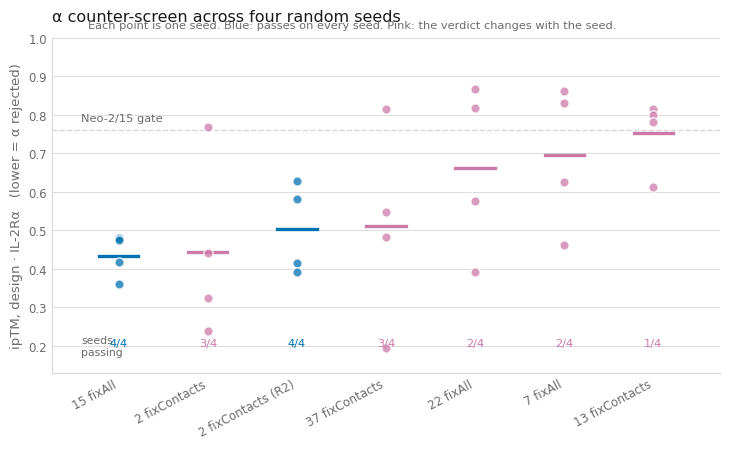

In [ ]:
# Per-design summary and the stability figure. A seed passes if it
# clears both of Neo-2/15's own alpha values (ipTM 0.761, interface
# PAE 14.31), seeds_passing out of four is the gate carried into the
# master table
import glob, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt

PROJ = "/content/drive/MyDrive/il2_mimetic"
FIG  = f"{PROJ}/figures"

DESIGNS = ["pad0_len100_2_fixContacts_3","pad0_len100_2_fixContacts_0",
           "pad0_len100_13_fixContacts_3","pad0_len100_15_fixAll_4",
           "pad0_len100_22_fixAll_0","pad0_len100_37_fixContacts_2",
           "pad2_len100_7_fixAll_3"]

def conf(job, seed):
    d = (f"{OUT}/boltz_results_{job}/predictions/{job}" if seed == 0 else
         f"{OUT}/seedtest_s{seed}/boltz_results_{job}/predictions/{job}")
    cj, pz = glob.glob(f"{d}/confidence*.json"), glob.glob(f"{d}/pae*.npz")
    if not cj: return None
    c = json.load(open(cj[0])); out = dict(seed=seed, iptm=c.get("iptm"))
    if pz:
        z = np.load(pz[0]); pae = np.squeeze(z[list(z.keys())[0]])
        rng, _ = blocks(job); ch = list(rng)
        out["pae"] = iface(pae, rng[ch[0]], rng[ch[1]])
    return out

rows = []
for d in DESIGNS:
    for s in (0,1,2,3):
        r = conf(f"{d}_alpha", s)
        if r: rows.append(dict(design=d, **r))
sd = pd.DataFrame(rows)

GATE_IPTM, GATE_PAE = 0.761, 14.31
summ = sd.groupby("design").agg(
    iptm_mean=("iptm","mean"), iptm_sd=("iptm","std"),
    pae_mean=("pae","mean"),  pae_sd=("pae","std"), n=("seed","count"))
summ["seeds_passing"] = sd.assign(
    ok=(sd.iptm < GATE_IPTM) & (sd.pae > GATE_PAE)
).groupby("design").ok.sum()
print(summ.round(3).to_string())
summ.round(4).to_csv(f"{PROJ}/stage5_complex/seed_replicates.tsv", sep="\t")

# ---- figure ----
INK, MUTED, RULE = "#1a1a1a", "#6b6b6b", "#d8d8d8"
PASS, FAIL = "#0072B2", "#CC79A7"

def shortn(d):
    p = d.split("_")
    return f"{p[2]} {p[3]}" + (" (R2)" if p[2] == "2" and p[4] == "0" else "")

order = summ.sort_values("iptm_mean").index.tolist()
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.axhline(GATE_IPTM, color=RULE, lw=1, ls="--", zorder=1)

# gate label on the LEFT, well clear of the high-scoring points on the right
ax.text(-0.42, GATE_IPTM + 0.018, "Neo-2/15 gate", ha="left", va="bottom",
        fontsize=8.2, color=MUTED, zorder=5)

for i, d in enumerate(order):
    v = sd[sd.design == d].iptm.values
    n_pass = int(summ.loc[d, "seeds_passing"])
    col = PASS if n_pass == len(v) else FAIL
    ax.plot([i-0.22, i+0.22], [v.mean()]*2, color=col, lw=2.4, zorder=3)
    ax.scatter([i]*len(v), v, s=44, color=col, alpha=0.75,
               edgecolor="white", linewidth=1.1, zorder=4)
    ax.text(i, 0.20, f"{n_pass}/{len(v)}", ha="center", fontsize=8.2,
            color=col, zorder=4)

ax.text(-0.42, 0.20, "seeds\npassing", ha="left", va="center",
        fontsize=7.8, color=MUTED)

ax.set_xticks(range(len(order)))
ax.set_xticklabels([shortn(d) for d in order], fontsize=8.6, rotation=28,
                   ha="right", color=INK)
ax.set_xlim(-0.75, len(order) - 0.25)
ax.set_ylabel("ipTM, design · IL-2Rα   (lower = α rejected)",
              fontsize=9.5, color=MUTED)
ax.set_ylim(0.13, 1.0)
ax.grid(axis="y", color=RULE, lw=0.6, zorder=0); ax.set_axisbelow(True)
for s in ("top","right"): ax.spines[s].set_visible(False)
for s in ("left","bottom"): ax.spines[s].set_color(RULE)
ax.tick_params(colors=MUTED, length=0, labelsize=8.5)

ax.set_title("α counter-screen across four random seeds", fontsize=11.5,
             color=INK, loc="left", pad=12)
fig.text(0.125, 0.925,
         "Each point is one seed. Blue: passes on every seed. "
         "Pink: the verdict changes with the seed.",
         fontsize=8.2, color=MUTED)

fig.tight_layout()
for ext in ("png","pdf"):
    fig.savefig(f"{FIG}/seed_stability.{ext}", dpi=300, bbox_inches="tight")
print("\nwrote", f"{FIG}/seed_stability.png")
plt.show()

In [ ]:
# Self-association screen: each sequence predicted against a copy of
# itself. A design that prefers its own surface to the receptor's is
# undevelopable whatever its receptor metrics say
import os, glob, subprocess, time
jobs = sorted(os.path.basename(p)[:-6]
              for p in glob.glob(f"{IN}/*_homodimer.fasta"))
def done(j):
    d = f"{OUT}/boltz_results_{j}/predictions/{j}"
    return bool(glob.glob(f"{d}/*.pdb")) and bool(glob.glob(f"{d}/pae*.npz"))
todo = [j for j in jobs if not done(j)]
print(f"{len(jobs)} homodimer jobs · {len(todo)} to run\n")

t0 = time.time()
for i, j in enumerate(todo, 1):
    t1 = time.time()
    p = subprocess.run(
        ["python","/content/tools/boltz_run.py","predict", f"{IN}/{j}.fasta",
         "--out_dir", OUT, "--output_format","pdb", "--seed","0",
         "--accelerator","gpu", "--use_msa_server", "--no_kernels",
         "--write_full_pae"], capture_output=True, text=True)
    print(f"[{i}/{len(todo)}] {'ok ' if done(j) else 'FAIL'} {j:46s} "
          f"{(time.time()-t1)/60:4.1f} min")
print(f"\ntotal {(time.time()-t0)/60:.1f} min")


9 homodimer jobs · 9 to run

[1/9] ok  ctrl_IL2_homodimer                              1.3 min
[2/9] ok  ctrl_Neo_homodimer                              1.2 min
[3/9] ok  pad0_len100_13_fixContacts_3_homodimer          1.2 min
[4/9] ok  pad0_len100_15_fixAll_4_homodimer               1.2 min
[5/9] ok  pad0_len100_22_fixAll_0_homodimer               1.2 min
[6/9] ok  pad0_len100_2_fixContacts_0_homodimer           1.2 min
[7/9] ok  pad0_len100_2_fixContacts_3_homodimer           1.2 min
[8/9] ok  pad0_len100_37_fixContacts_2_homodimer          1.2 min
[9/9] ok  pad2_len100_7_fixAll_3_homodimer                1.2 min

total 11.0 min


In [ ]:
# Self-association results. Note the positive control: native IL-2 is
# monomeric in solution and scores highest in the panel, which is
# discussed below
import json, glob, numpy as np, pandas as pd
rows = []
for j in sorted(os.path.basename(p)[:-6] for p in glob.glob(f"{IN}/*_homodimer.fasta")):
    d = f"{OUT}/boltz_results_{j}/predictions/{j}"
    cj, pz = glob.glob(f"{d}/confidence*.json"), glob.glob(f"{d}/pae*.npz")
    if not cj: continue
    c = json.load(open(cj[0]))
    r = dict(design=j.replace("_homodimer",""), iptm=c.get("iptm"),
             plddt=c.get("complex_plddt"))
    if pz:
        z = np.load(pz[0]); pae = np.squeeze(z[list(z.keys())[0]])
        rng, _ = blocks(j); ch = list(rng)
        r["pae_self"] = iface(pae, rng[ch[0]], rng[ch[1]])
    rows.append(r)
hd = pd.DataFrame(rows).set_index("design")
order = ["ctrl_IL2","ctrl_Neo"] + sorted(d for d in hd.index if not d.startswith("ctrl_"))
print(hd.reindex([o for o in order if o in hd.index]).round(3).to_string())
hd.round(4).to_csv(f"{PROJ}/stage5_complex/homodimer_metrics.tsv", sep="\t")

                               iptm  plddt  pae_self
design                                              
ctrl_IL2                      0.869  0.861     5.787
ctrl_Neo                      0.336  0.807    16.042
pad0_len100_13_fixContacts_3  0.445  0.913    13.989
pad0_len100_15_fixAll_4       0.207  0.707    21.485
pad0_len100_22_fixAll_0       0.309  0.906    18.415
pad0_len100_2_fixContacts_0   0.597  0.939    10.847
pad0_len100_2_fixContacts_3   0.347  0.880    18.555
pad0_len100_37_fixContacts_2  0.354  0.922    16.371
pad2_len100_7_fixAll_3        0.426  0.900    15.394


#### Results
1. The α binding site is not reproducible between seeds

| | buried area (Å²) | range | contact-residue overlap between seeds |
|---|---|---|---|
| 2_fixContacts_3 | 961 ± 194 | 769-1202 | Jaccard 0.42 (min 0.26) |
| 2_fixContacts_0 | 1031 ± 142 | 939-1277 | Jaccard 0.42 (min 0.34) |

Two predictions of the identical complex share fewer than half their interface residues, and the buried area varies by over 400 Å², which is a factor of 1.6. The model is not uncertain about how good an interface it has built, but it is just building different interface each time.

2. Replicated verdicts differ from single-seed verdicts
Seeds passing both of Neo-2/15's α thresholds, out of four:

| design | ipTM mean ± SD | PAE mean ± SD | seeds passing |
|---|---|---|---|
| 15_fixAll_4 | 0.433 ± 0.057 | 20.58 ± 1.62 | 4 |
| 2_fixContacts_0 (R2) | 0.503 ± 0.117 | 18.31 ± 2.29 | 4 |
| 2_fixContacts_3 | 0.443 ± 0.232 | 19.55 ± 5.32 | 3 |
| 37_fixContacts_2 | 0.510 ± 0.255 | 18.34 ± 4.93 | 3 |
| 22_fixAll_0 | 0.662 ± 0.221 | 14.65 ± 4.24 | 2 |
| 7_fixAll_3 | 0.694 ± 0.188 | 13.74 ± 5.92 | 2 |
| 13_fixContacts_3 | 0.752 ± 0.093 | 13.51 ± 2.43 | 1 |

The two designs most consistently α-averse are 15_fixAll_4, which has the worst target engagement in the whole panel (interface PAE 11 1, worse than the scrambled control), and the post-hoc Round 2 addition. Standard deviations of 0.19-0.26 on a metric whose control range is 0.18 mean the ordering below the top two is not resolvable.

3. The Round 2 substitution worked
`_0` differs from `_3` at one position: tyrosine rather than arginine at 22. Buried unsatisfied sidechain polars fall from 3 to 2, and Arg22's NE and NH1. Target engagement is slightly better (interface PAE 5.73/5.93 against 6.08/6.14) and the α panel is more stable across seeds (SD 0.117 against 0.232).

Position 22 is absent from the α-contacting residue set in both siblings, confirming that the substitution addressed core packing and did not alter the counter-screen surface. The two effects are separable, which is why the comparison means anything.

4. The self-association screen fails its positive control

| | self ipTM | self-interface PAE |
|---|---|---|
| native IL-2 | 0.869 | 5.79 |
| Neo-2/15 | 0.336 | 16.04 |
| designs | 0.207-0.597 | 10.85-21.49 |

Native IL-2 is monomeric in solution. It scores as the most strongly self-associating
molecule in the panel, by a wide margin, with a confidently predicted interface. This is a
false positive on the one molecule whose answer is known.

The likely cause is the MSA asymmetry: native IL-2 was the only ligand given a server MSA,
matching how it was treated in Stage 5, and MSA-driven predictions of cytokine homodimers
are a known failure mode. Neo-2/15, predicted in single-sequence mode like the designs,
gives the correct answer for a monomer.

Consequently, the self-association gate used downstream (0.45) is anchored on Neo-2/15 rather
than on native IL-2, and is marked post-hoc in the master table. The native control is
reported rather than quietly dropped, because it is the reason the gate had to be chosen
that way.

5. The grafted motif cannot be recovered from sequence identity

Inferring the grafted positions by aligning a design against IL-2 and keeping identical runs
gives 9 residues in one segment. Reading con_hal_idx0 from the .trb gives 36
positions across three segments (10-21, 54-65, 94-105).

The identity method undercounts four-fold because fixContacts released 15 of the 36
positions for redesign. They remain geometrically constrained but no longer match IL-2's sequence. Structural constraint and sequence identity are distinct properties, and only the first was ever recorded. The first attempt is retained because the error is instructive: the render it produced looked plausible.
